# NF-CICIDS2018 v3 Dataset Analysis

**Repository**: TRENCH-IDS Research  
**Dataset**: `data/CICIDS/NF-CICIDS2018-v3/data/NF-CICIDS2018-v3.csv`  
**Feature reference**: `v3/CICIDS/NF-CICIDS2018-v3/data/NetFlow_v3_Features.csv`

## Who this notebook is for

Anyone who wants a complete, beginner-friendly picture of the NF-CICIDS2018 v3 dataset. Every cell does **one small thing** and explains what it shows.

## What you will learn

- What a network **flow** is and what the 55 columns mean
- Exact benign vs. attack counts over the full dataset
- Every attack sub-type, checked **all at once or one at a time**
- **Whether attacks come in blocks or are mixed** once benign traffic is removed
- Protocol, port, IP and time-of-day patterns
- How benign and attack flows differ in size, duration and speed

> **Important:** the CSV is stored in time order. The first rows cover only the first capture days, so they miss most attack types. That is why this notebook scans the **full file once** before doing attack-level analysis.


In [ ]:
import os
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

candidates = [
    'data/CICIDS/NF-CICIDS2018-v3/data/NF-CICIDS2018-v3.csv',
    '../data/CICIDS/NF-CICIDS2018-v3/data/NF-CICIDS2018-v3.csv',
    '../../data/CICIDS/NF-CICIDS2018-v3/data/NF-CICIDS2018-v3.csv',
    '../../../data/CICIDS/NF-CICIDS2018-v3/data/NF-CICIDS2018-v3.csv',
]
DATA_PATH = next((c for c in candidates if os.path.exists(c)), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset not found. Tried: ' + str(candidates))

FEATURES_PATH = os.path.join(os.path.dirname(DATA_PATH), 'NetFlow_v3_Features.csv')
print('Using dataset :', DATA_PATH)
print('Using features:', FEATURES_PATH)

Using dataset : ../../../data/CICIDS/NF-CICIDS2018-v3/data/NF-CICIDS2018-v3.csv
Using features: ../../../v3/CICIDS/NF-CICIDS2018-v3/data\NetFlow_v3_Features.csv


## What is this dataset?

NF-CICIDS2018 v3 is a **network-flow** dataset for intrusion detection, derived from the CSE-CIC-IDS2018 capture.

- A **flow** is one conversation between a source and a destination (same IPs, ports and protocol).
- Each **row** is one flow.
- Each **column** is one measurement about that flow.

### Size and labels

| Item | Value |
|---|---|
| Rows (flows) | ~20.1 million |
| Capture period | 14 Feb 2018 to 2 Mar 2018 |
| Columns | 55 = 53 flow measurements + 2 labels |
| `Label` | `0` = benign, `1` = attack |
| `Attack` | Attack sub-type name (benign rows say `Benign`) |

There are **14 attack sub-types**. The capture ran one or two attack scenarios per day, which is why the ordering analysis later finds clean, day-sized blocks.

### Attack sub-types

| Attack | Meaning |
|---|---|
| `DDOS_attack-HOIC` | HTTP flood using the HOIC DDoS tool |
| `DDoS_attacks-LOIC-HTTP` | HTTP flood using the LOIC tool |
| `DDOS_attack-LOIC-UDP` | UDP flood using the LOIC tool |
| `DoS_attacks-GoldenEye` | HTTP DoS that keeps connections open (GoldenEye) |
| `DoS_attacks-Hulk` | HTTP flood that requests unique URLs (Hulk) |
| `DoS_attacks-SlowHTTPTest` | Slow HTTP POST / header attack |
| `DoS_attacks-Slowloris` | Slowloris: many half-open HTTP connections |
| `FTP-BruteForce` | Password guessing against FTP |
| `SSH-Bruteforce` | Password guessing against SSH |
| `Brute_Force_-Web` | Brute-force login attempts against a web app |
| `Brute_Force_-XSS` | Cross-site scripting attempts in the web scenario |
| `SQL_Injection` | SQL injection against a web app |
| `Infilteration` | Infiltration and lateral movement inside the network |
| `Bot` | Botnet command-and-control traffic |

> The label spellings above (`Infilteration`, `DDOS`, `Bruteforce`, ...) are copied **exactly** from the dataset. Do not "fix" them in code.


## 1. Feature reference

`NetFlow_v3_Features.csv` explains every one of the 53 measurement columns.


In [3]:
features_df = pd.read_csv(FEATURES_PATH)
print(f'Documented flow features: {len(features_df)}')
print(f'Plus 2 labels -> {len(features_df) + 2} total columns')
features_df.head(10)


Documented flow features: 53
Plus 2 labels -> 55 total columns


,Feature,Description
0,IPV4_SRC_ADDR,IPv4 source address
1,IPV4_DST_ADDR,IPv4 destination address
2,L4_SRC_PORT,IPv4 source port number
3,L4_DST_PORT,IPv4 destination port number
4,PROTOCOL,IP protocol identifier byte
5,L7_PROTO,Layer 7 protocol (numeric)
6,IN_BYTES,Incoming number of bytes
7,OUT_BYTES,Outgoing number of bytes
8,IN_PKTS,Incoming number of packets
9,OUT_PKTS,Outgoing number of packets


## 2. First look at the raw file

Load the first 1,000,000 rows to inspect the schema. This keeps memory small and preserves row order.


In [4]:
SAMPLE_ROWS = 1_000_000
df_sample = pd.read_csv(DATA_PATH, nrows=SAMPLE_ROWS)

print(f'Sample: {len(df_sample):,} rows x {df_sample.shape[1]} columns')
df_sample.head(3)


Sample: 1,000,000 rows x 55 columns


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1518611287705,1518611287705,172.31.0.2,53,172.31.66.58,63593,17,5,156,1,...,0,0,0,0,0,0,0,0,0,Benign
1,1518611287743,1518611290747,172.31.66.58,56163,239.255.255.250,1900,17,12,805,5,...,0,2793,750,1182,0,0,0,0,0,Benign
2,1518611288143,1518611300202,172.31.66.46,62388,239.255.255.250,1900,17,12,1288,8,...,0,3016,1722,1436,0,0,0,0,0,Benign


### Why the first sample is not enough

Because the file is **time-ordered**, the first 1M rows cover only the first capture day. They contain **one** attack type (`FTP-BruteForce`) out of 14, and attacks are over-represented (33% of rows vs 13% in the full file). Check it below.


In [5]:
sample_attacks = (
    df_sample.loc[df_sample['Label'] == 1, 'Attack']
    .value_counts()
    .rename_axis('Attack')
    .to_frame('Flows')
)
print('Attack types in the first 1M rows:')
display(sample_attacks)
print('Only the first capture window is visible here, so full-file scanning is required.')


Attack types in the first 1M rows:


,Flows
Attack,
FTP-BruteForce,330960


Only the first capture window is visible here, so full-file scanning is required.


## 3. Column groups at a glance

The 55 columns belong to a few logical families. This is the vocabulary an IDS model sees.


In [6]:
feature_groups = {
    'Addresses': ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR'],
    'Ports': ['L4_SRC_PORT', 'L4_DST_PORT'],
    'Protocol': ['PROTOCOL', 'L7_PROTO'],
    'Traffic volume': ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS'],
    'Duration': ['FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT'],
    'TCP flags': ['TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS'],
    'TTL': ['MIN_TTL', 'MAX_TTL'],
    'Packet size': ['LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN'],
    'Retransmissions': ['RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS',
                        'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS'],
    'Throughput': ['SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT'],
    'Bytes/sec': ['SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES'],
    'Packet-size histogram': ['NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES',
                              'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES',
                              'NUM_PKTS_1024_TO_1514_BYTES'],
    'TCP window': ['TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT'],
    'ICMP/DNS/FTP': ['ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID',
                     'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE'],
    'Timestamps': ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS'],
    'Inter-arrival time': ['SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX',
                           'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV',
                           'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX',
                           'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV'],
    'Labels': ['Label', 'Attack'],
}

for group, cols in feature_groups.items():
    present = [c for c in cols if c in df_sample.columns]
    print(f'{group:22s}: {len(present)}')
print('Total accounted for :', sum(len([c for c in v if c in df_sample.columns])
                                   for v in feature_groups.values()))


Addresses             : 2
Ports                 : 2
Protocol              : 2
Traffic volume        : 4
Duration              : 3
TCP flags             : 3
TTL                   : 2
Packet size           : 4
Retransmissions       : 4
Throughput            : 2
Bytes/sec             : 2
Packet-size histogram : 5
TCP window            : 2
ICMP/DNS/FTP          : 6
Timestamps            : 2
Inter-arrival time    : 8
Labels                : 2
Total accounted for : 55


## 4. One full-dataset scan

This single pass over the CSV collects everything the rest of the notebook needs:

1. Exact `Label` and `Attack` counts for every row.
2. The complete **attack sequence** (start time + attack type) for ordering analysis.
3. A **stratified sample of every attack type** (up to 20k rows each) for per-attack feature stats.
4. Full-file protocol and port counters.

It streams in 500k-row chunks, so memory stays modest.


In [7]:
MAX_PER_TYPE = 20_000
SCAN_COLS = [
    'FLOW_START_MILLISECONDS', 'Attack', 'Label',
    'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS',
    'FLOW_DURATION_MILLISECONDS', 'PROTOCOL', 'L4_SRC_PORT', 'L4_DST_PORT',
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR',
    'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT',
    'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT',
]

label_counts = Counter()
attack_counts = Counter()
proto_counts = Counter()
dst_port_counts = Counter()
src_port_counts = Counter()

attack_to_code = {}
code_parts, time_parts, sample_parts = [], [], []
sampled = {}
total_rows = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=500_000, usecols=SCAN_COLS):
    total_rows += len(chunk)
    label_counts.update(chunk['Label'].value_counts().to_dict())
    proto_counts.update(chunk['PROTOCOL'].value_counts().to_dict())
    dst_port_counts.update(chunk['L4_DST_PORT'].value_counts().to_dict())
    src_port_counts.update(chunk['L4_SRC_PORT'].value_counts().to_dict())

    atk = chunk[chunk['Label'] == 1]
    if len(atk) == 0:
        continue

    attack_counts.update(atk['Attack'].value_counts().to_dict())
    for name in atk['Attack'].unique():
        attack_to_code.setdefault(name, len(attack_to_code))

    code_parts.append(atk['Attack'].map(attack_to_code).to_numpy(dtype=np.int16))
    time_parts.append(atk['FLOW_START_MILLISECONDS'].to_numpy(dtype=np.int64))

    for name, group in atk.groupby('Attack', sort=False):
        have = sampled.get(name, 0)
        if have < MAX_PER_TYPE:
            take = group.head(MAX_PER_TYPE - have)
            sample_parts.append(take)
            sampled[name] = have + len(take)

    if total_rows % 5_000_000 < 500_000:
        print(f'  scanned {total_rows:,} rows ...')

attack_codes = np.concatenate(code_parts)
attack_times = np.concatenate(time_parts)
df_attacks = pd.concat(sample_parts, ignore_index=True)
code_to_attack = {v: k for k, v in attack_to_code.items()}

# Put attacks in true time order (CSV is nearly ordered; sorting is safe).
order = np.argsort(attack_times, kind='stable')
attack_times = attack_times[order]
attack_codes = attack_codes[order]

print(f'Full rows          : {total_rows:,}')
print(f'Attack flows       : {len(attack_codes):,}')
print(f'Attack types       : {len(attack_to_code)} -> {sorted(attack_to_code)}')
print(f'Stratified sample  : {len(df_attacks):,} attack rows')


  scanned 5,000,000 rows ...
  scanned 10,000,000 rows ...
  scanned 15,000,000 rows ...
  scanned 20,000,000 rows ...
  scanned 20,115,529 rows ...
Full rows          : 20,115,529
Attack flows       : 2,600,903
Attack types       : 14 -> ['Bot', 'Brute_Force_-Web', 'Brute_Force_-XSS', 'DDOS_attack-HOIC', 'DDOS_attack-LOIC-UDP', 'DDoS_attacks-LOIC-HTTP', 'DoS_attacks-GoldenEye', 'DoS_attacks-Hulk', 'DoS_attacks-SlowHTTPTest', 'DoS_attacks-Slowloris', 'FTP-BruteForce', 'Infilteration', 'SQL_Injection', 'SSH-Bruteforce']
Stratified sample  : 205,988 attack rows


## 5. Binary label distribution (full dataset)

Exact benign vs. attack counts across every row.


,Label,Flows,Class,Percent
0,0,17514626,Benign,87.07
1,1,2600903,Attack,12.93


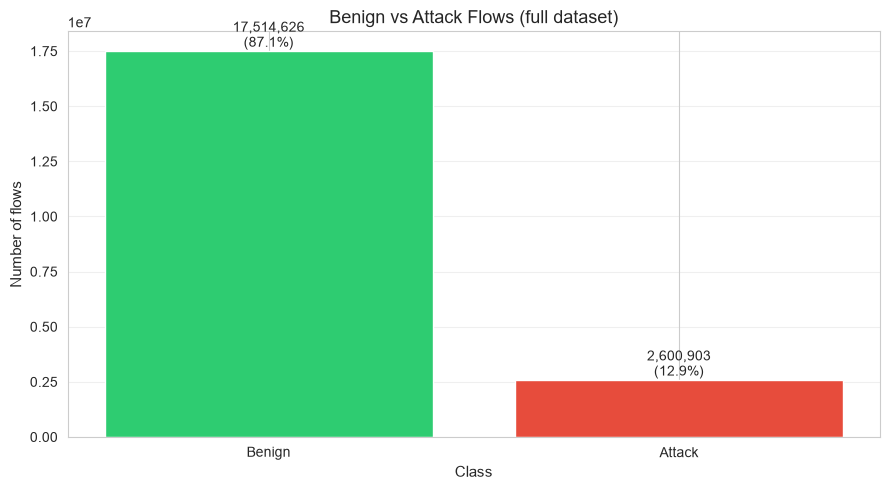

In [8]:
label_df = pd.DataFrame(
    [(int(k), v) for k, v in label_counts.items()],
    columns=['Label', 'Flows'],
)
label_df['Class'] = label_df['Label'].map({0: 'Benign', 1: 'Attack'})
label_df['Percent'] = (label_df['Flows'] / total_rows * 100).round(2)
label_df = label_df.sort_values('Flows', ascending=False)
display(label_df)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2ecc71' if c == 'Benign' else '#e74c3c' for c in label_df['Class']]
bars = ax.bar(label_df['Class'], label_df['Flows'], color=colors)
ax.set_xlabel('Class')
ax.set_ylabel('Number of flows')
ax.set_title('Benign vs Attack Flows (full dataset)')
for bar, pct in zip(bars, label_df['Percent']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{bar.get_height():,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Attack sub-type distribution (full dataset)

Attack rows only (benign removed). This is the table the rest of the notebook uses.


,Attack,Flows,PercentOfAttacks
0,DDOS_attack-HOIC,1032311,39.69
1,FTP-BruteForce,386720,14.87
2,DDoS_attacks-LOIC-HTTP,288589,11.10
3,Bot,207703,7.99
4,SSH-Bruteforce,188474,7.25
5,Infilteration,188152,7.23
6,DoS_attacks-SlowHTTPTest,105550,4.06
7,DoS_attacks-Hulk,100076,3.85
8,DoS_attacks-GoldenEye,61300,2.36
9,DoS_attacks-Slowloris,36040,1.39


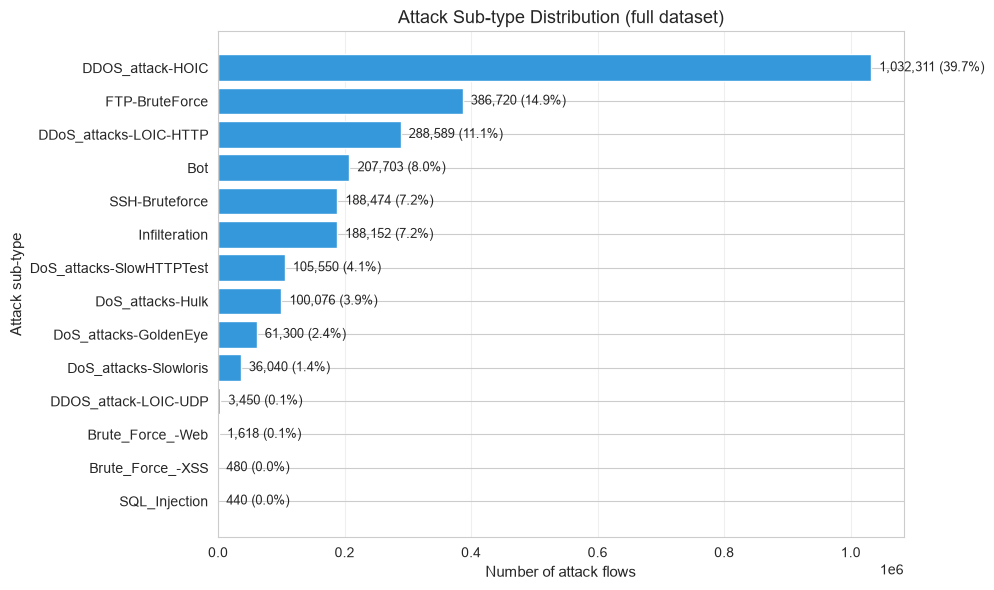

In [9]:
attack_df = pd.DataFrame(
    [(k, v) for k, v in attack_counts.items()],
    columns=['Attack', 'Flows'],
).sort_values('Flows', ascending=False)
attack_df['PercentOfAttacks'] = (attack_df['Flows'] / attack_df['Flows'].sum() * 100).round(2)
display(attack_df.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(attack_df['Attack'][::-1], attack_df['Flows'][::-1], color='#3498db')
ax.set_xlabel('Number of attack flows')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Sub-type Distribution (full dataset)')
for i, (v, p) in enumerate(zip(attack_df['Flows'][::-1], attack_df['PercentOfAttacks'][::-1])):
    ax.text(v, i, f'  {v:,} ({p:.1f}%)', va='center', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Attack ordering: sequential or mixed?

**Question:** after removing benign flows, do the same attacks arrive in long blocks, or are different attacks interleaved?

- `runs` = number of consecutive blocks of the same attack type.
- **Mixing index** = `(runs - 1) / (attack flows - 1)`.
  - `0.0` → one huge block (fully sequential).
  - `1.0` → the attack type changes at every single flow (fully mixed).

This uses the **full attack sequence**, not the first 1M rows, so every attack type is included.

> A single overall number can hide local structure. A dataset can be 99.9% sequential and still contain one short, heavily mixed episode. That is exactly what happens here, so the next cells also show **runs per attack**.


In [10]:
change = np.r_[True, attack_codes[1:] != attack_codes[:-1]]
run_starts = np.flatnonzero(change)
run_lengths = np.diff(np.r_[run_starts, len(attack_codes)])
run_types = attack_codes[run_starts]

n_flows = len(attack_codes)
n_runs = len(run_lengths)
mixing_index = (n_runs - 1) / (n_flows - 1)

print(f'Attack flows        : {n_flows:,}')
print(f'Consecutive blocks  : {n_runs:,}')
print(f'Mean block length   : {run_lengths.mean():,.1f} flows')
print(f'Median block length : {np.median(run_lengths):,.0f} flows')
print(f'Longest block       : {run_lengths.max():,} flows')
print(f'Mixing index        : {mixing_index:.4f}')

if mixing_index < 0.3:
    verdict = 'mostly BLOCKED / sequential'
elif mixing_index > 0.7:
    verdict = 'strongly MIXED'
else:
    verdict = 'PARTIALLY mixed'
print(f'Verdict             : {verdict}')


Attack flows        : 2,600,903
Consecutive blocks  : 1,294
Mean block length   : 2,010.0 flows
Median block length : 1 flows
Longest block       : 1,032,311 flows
Mixing index        : 0.0005
Verdict             : mostly BLOCKED / sequential


In [11]:
n_types = len(attack_to_code)
run_count = np.bincount(run_types, minlength=n_types)
run_sum = np.bincount(run_types, weights=run_lengths, minlength=n_types)
run_max = np.zeros(n_types, dtype=np.int64)
np.maximum.at(run_max, run_types, run_lengths)

run_table = pd.DataFrame({
    'Runs': run_count,
    'MeanRun': np.divide(run_sum, run_count, out=np.zeros(n_types), where=run_count > 0),
    'MaxRun': run_max,
}, index=[code_to_attack[i] for i in range(n_types)])
run_table.index.name = 'Attack'
run_table = run_table.sort_values('Runs', ascending=False).round(1)
display(run_table)


,Runs,MeanRun,MaxRun
Attack,,,
Brute_Force_-Web,467,3.5,30
Brute_Force_-XSS,451,1.1,3
SQL_Injection,365,1.2,6
DoS_attacks-GoldenEye,1,61300.0,61300
FTP-BruteForce,1,386720.0,386720
SSH-Bruteforce,1,188474.0,188474
DoS_attacks-Hulk,1,100076.0,100076
DoS_attacks-SlowHTTPTest,1,105550.0,105550
DoS_attacks-Slowloris,1,36040.0,36040


### Chronological block order

There are 1,294 blocks in total. **11 of the 14 attack types appear as exactly one contiguous block each**, and those 11 blocks cover **99.9%** of all attack flows. The three small web attacks are the exception: they alternate with each other on 22 Feb.

The table and Gantt chart below show the 11 major blocks. The next cells zoom into the mixed web-attack episode.


In [12]:
block_rows = []
for k, start in enumerate(run_starts):
    end = start + run_lengths[k] - 1
    block_rows.append({
        'Order': k + 1,
        'Attack': code_to_attack[int(run_types[k])],
        'Flows': int(run_lengths[k]),
        'Start': pd.to_datetime(int(attack_times[start]), unit='ms'),
        'End': pd.to_datetime(int(attack_times[end]), unit='ms'),
        'Duration_min': round((int(attack_times[end]) - int(attack_times[start])) / 60_000, 2),
    })
block_df = pd.DataFrame(block_rows)

# Show only the big scenario blocks in the table and Gantt chart.
major_blocks = block_df[block_df['Flows'] >= 1_000].copy()
major_blocks['Order'] = range(1, len(major_blocks) + 1)
print(f'Total blocks         : {len(block_df):,}')
print(f'Major blocks (>=1k)  : {len(major_blocks):,}')
print(f'Flows in major blocks: {major_blocks["Flows"].sum():,} '
      f'({major_blocks["Flows"].sum() / n_flows * 100:.2f}% of attacks)')
display(major_blocks.reset_index(drop=True))


Total blocks         : 1,294
Major blocks (>=1k)  : 11
Flows in major blocks: 2,598,365 (99.90% of attacks)


,Order,Attack,Flows,Start,End,Duration_min
0,1,FTP-BruteForce,386720,2018-02-14 14:33:26.718,2018-02-14 16:10:31.996,97.09
1,2,SSH-Bruteforce,188474,2018-02-14 18:01:21.199,2018-02-14 19:32:30.288,91.15
2,3,DoS_attacks-GoldenEye,61300,2018-02-15 13:27:42.466,2018-02-15 14:11:45.874,44.06
3,4,DoS_attacks-Slowloris,36040,2018-02-15 15:00:12.551,2018-02-15 15:41:34.482,41.37
4,5,DoS_attacks-SlowHTTPTest,105550,2018-02-16 14:12:14.134,2018-02-16 15:05:13.888,53.00
5,6,DoS_attacks-Hulk,100076,2018-02-16 17:45:27.826,2018-02-16 17:58:22.098,12.90
6,7,DDoS_attacks-LOIC-HTTP,288589,2018-02-20 14:13:54.662,2018-02-20 17:29:16.047,195.36
7,8,DDOS_attack-LOIC-UDP,3450,2018-02-21 14:08:51.251,2018-02-21 14:43:16.845,34.43
8,9,DDOS_attack-HOIC,1032311,2018-02-21 18:11:08.829,2018-02-21 19:05:54.052,54.75
9,10,Infilteration,188152,2018-02-28 12:22:05.767,2018-03-01 21:40:18.782,1998.22


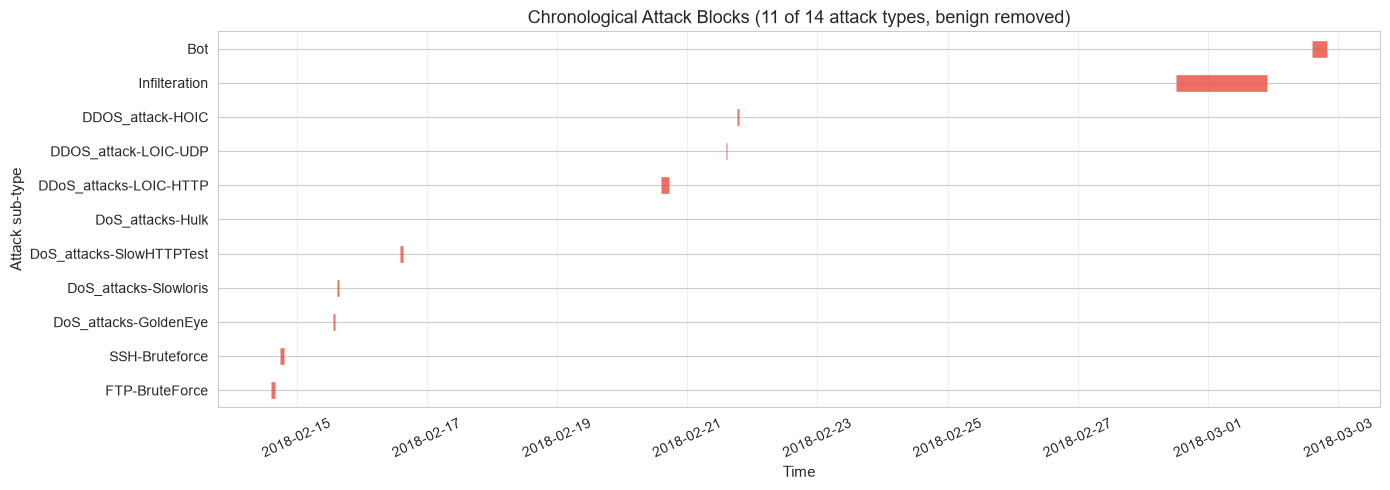

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
for _, row in major_blocks.iterrows():
    ax.hlines(row['Attack'], row['Start'], row['End'],
              linewidth=12, color='#e74c3c', alpha=0.8)
ax.set_xlabel('Time')
ax.set_ylabel('Attack sub-type')
ax.set_title('Chronological Attack Blocks (11 of 14 attack types, benign removed)')
ax.grid(axis='x', alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


#### How mixed is the web episode?

`Brute_Force_-Web`, `Brute_Force_-XSS` and `SQL_Injection` all occur on **22 Feb 2018**. They alternate in tiny bursts of a few flows, which produces 1,283 of the 1,294 blocks even though these three attacks are only 0.1% of all attack flows. The zoom below shows every one of their flows.


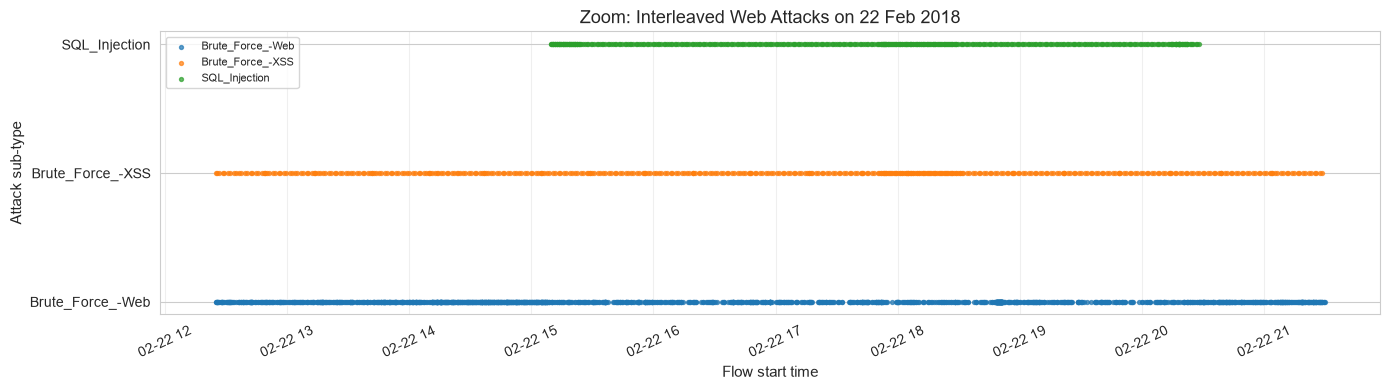

Web-attack flows shown: 2,538


In [14]:
web_names = ['Brute_Force_-Web', 'Brute_Force_-XSS', 'SQL_Injection']
web_flows = (df_attacks[df_attacks['Attack'].isin(web_names)]
             .sort_values('FLOW_START_MILLISECONDS'))
web_times = pd.to_datetime(web_flows['FLOW_START_MILLISECONDS'], unit='ms')

fig, ax = plt.subplots(figsize=(14, 4))
for i, name in enumerate(web_names):
    mask = (web_flows['Attack'] == name).to_numpy()
    ax.scatter(web_times[mask], np.full(mask.sum(), i), s=8, alpha=0.7, label=name)
ax.set_yticks(range(len(web_names)))
ax.set_yticklabels(web_names)
ax.set_xlabel('Flow start time')
ax.set_ylabel('Attack sub-type')
ax.set_title('Zoom: Interleaved Web Attacks on 22 Feb 2018')
ax.legend(loc='upper left', fontsize=8)
ax.grid(axis='x', alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print(f'Web-attack flows shown: {len(web_flows):,}')


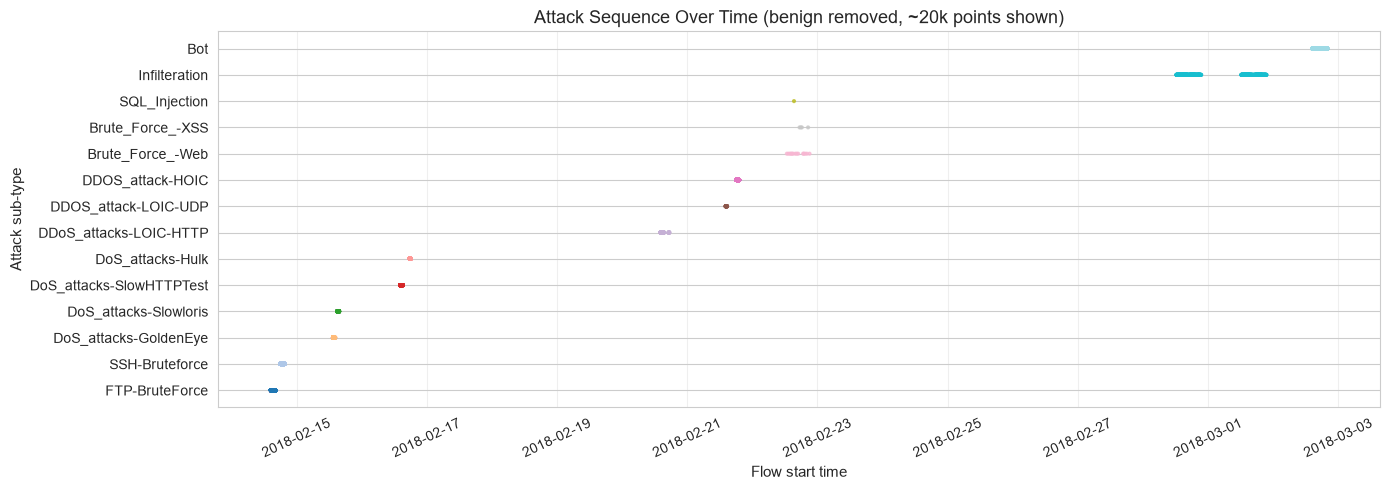

In [15]:
step = max(1, n_flows // 20_000)
tl_time = pd.to_datetime(attack_times[::step], unit='ms')
tl_code = attack_codes[::step]

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(tl_time, tl_code, c=tl_code, cmap='tab20', s=4, alpha=0.75)
ax.set_yticks(range(n_types))
ax.set_yticklabels([code_to_attack[i] for i in range(n_types)])
ax.set_xlabel('Flow start time')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Sequence Over Time (benign removed, ~20k points shown)')
ax.grid(axis='x', alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


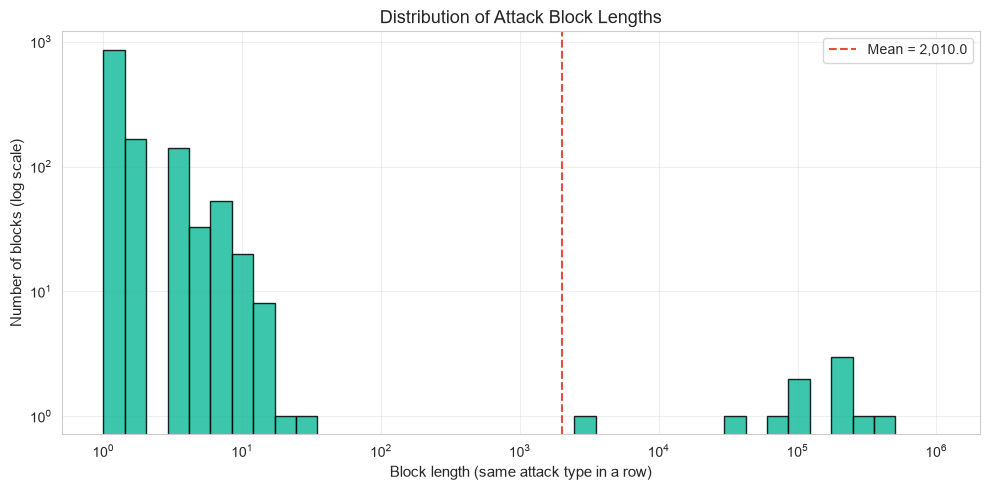

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.logspace(0, np.log10(max(int(run_lengths.max()), 2)), 40)
ax.hist(run_lengths, bins=bins, color='#1abc9c', edgecolor='black', alpha=0.85)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Block length (same attack type in a row)')
ax.set_ylabel('Number of blocks (log scale)')
ax.set_title('Distribution of Attack Block Lengths')
ax.axvline(run_lengths.mean(), color='#e74c3c', linestyle='--',
           label=f'Mean = {run_lengths.mean():,.1f}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,FTP-BruteForce,SSH-Bruteforce,DoS_attacks-GoldenEye,DoS_attacks-Slowloris,DoS_attacks-SlowHTTPTest,DoS_attacks-Hulk,DDoS_attacks-LOIC-HTTP,DDOS_attack-LOIC-UDP,DDOS_attack-HOIC,Brute_Force_-Web,Brute_Force_-XSS,SQL_Injection,Infilteration,Bot
FTP-BruteForce,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SSH-Bruteforce,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DoS_attacks-GoldenEye,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DoS_attacks-Slowloris,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DoS_attacks-SlowHTTPTest,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DoS_attacks-Hulk,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DDoS_attacks-LOIC-HTTP,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DDOS_attack-LOIC-UDP,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
DDOS_attack-HOIC,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0
Brute_Force_-Web,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,71.1,11.0,17.8,0.1,0.0


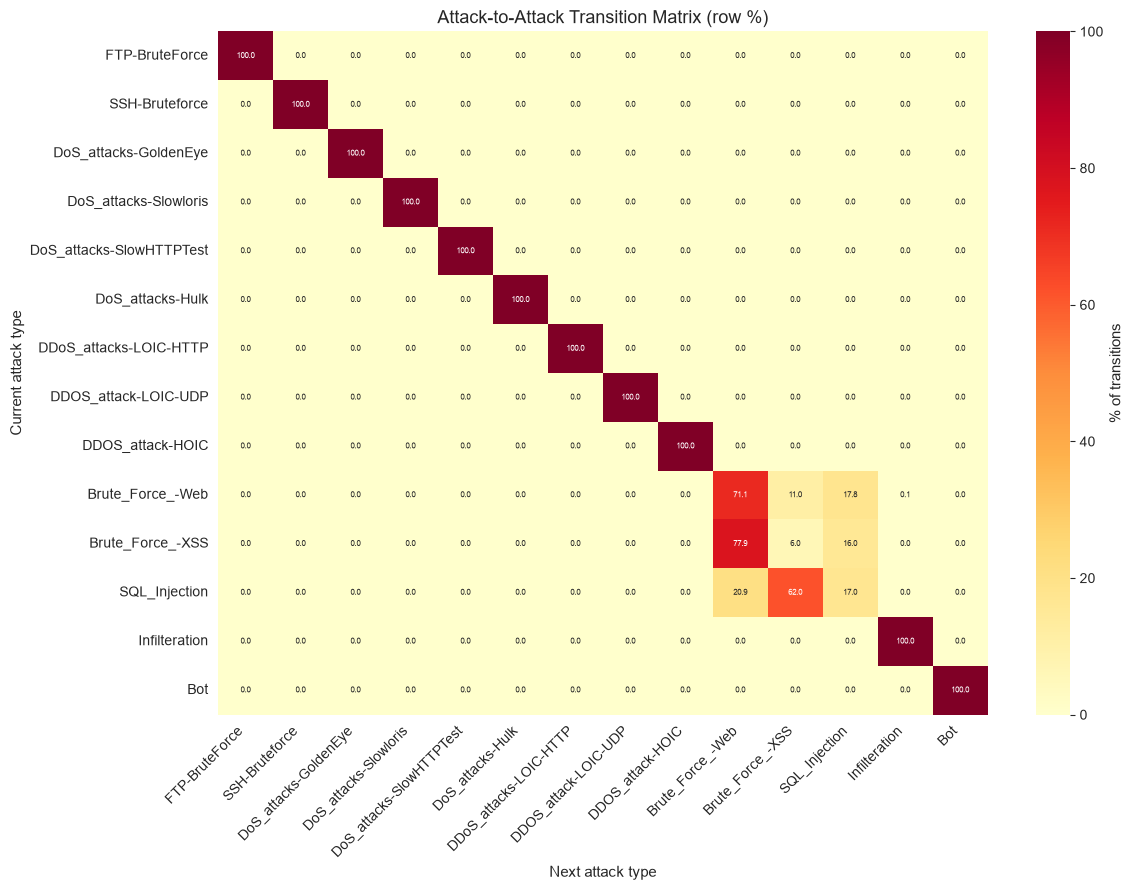

In [17]:
pair_index = attack_codes[:-1].astype(np.int64) * n_types + attack_codes[1:]
trans = np.bincount(pair_index, minlength=n_types * n_types).reshape(n_types, n_types)
row_sums = trans.sum(axis=1, keepdims=True)
trans_pct = np.divide(trans, row_sums,
                      out=np.zeros_like(trans, dtype=float), where=row_sums > 0) * 100

names = [code_to_attack[i] for i in range(n_types)]
trans_df = pd.DataFrame(trans_pct.round(1), index=names, columns=names)
display(trans_df)

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(trans_df, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
            annot_kws={'size': 6}, cbar_kws={'label': '% of transitions'})
ax.set_xlabel('Next attack type')
ax.set_ylabel('Current attack type')
ax.set_title('Attack-to-Attack Transition Matrix (row %)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Attack volume by capture day

The capture ran one or two scenarios per day, so a date-by-attack heatmap shows the campaign schedule more clearly than hour-of-day alone.


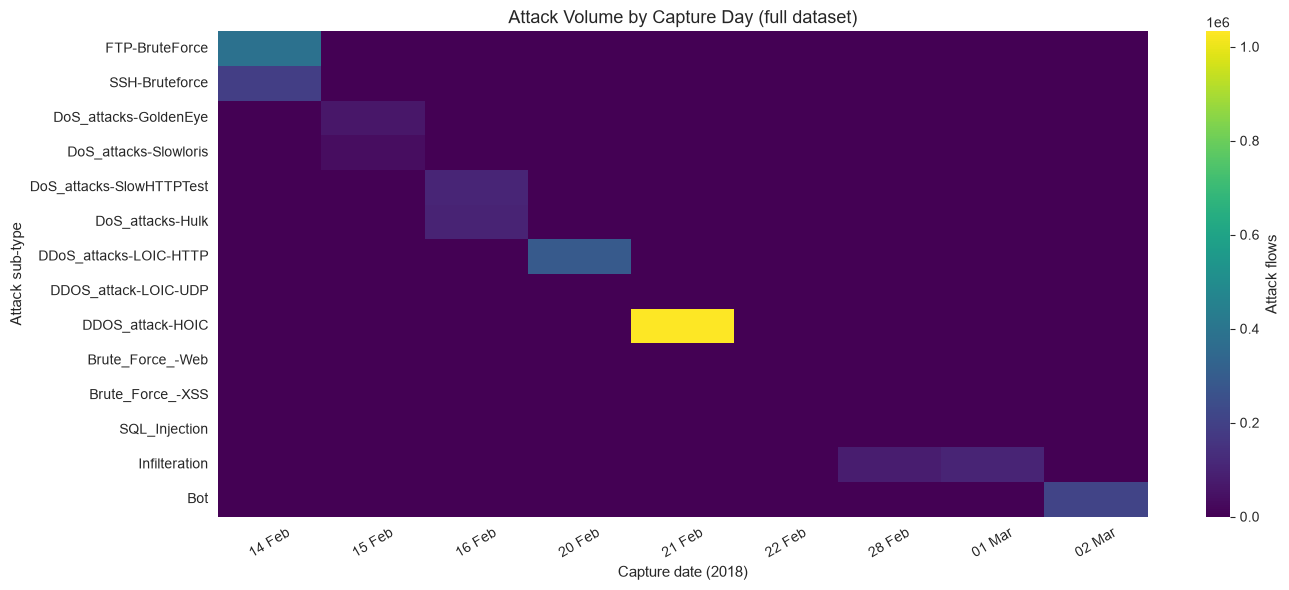

In [18]:
attack_dates = pd.to_datetime(attack_times, unit='ms').date
date_table = pd.crosstab(attack_dates, attack_codes)
date_table.index = pd.to_datetime(date_table.index).strftime('%d %b')
date_table.columns = [code_to_attack[c] for c in date_table.columns]

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(date_table.T, cmap='viridis', ax=ax,
            cbar_kws={'label': 'Attack flows'})
ax.set_xlabel('Capture date (2018)')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Volume by Capture Day (full dataset)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


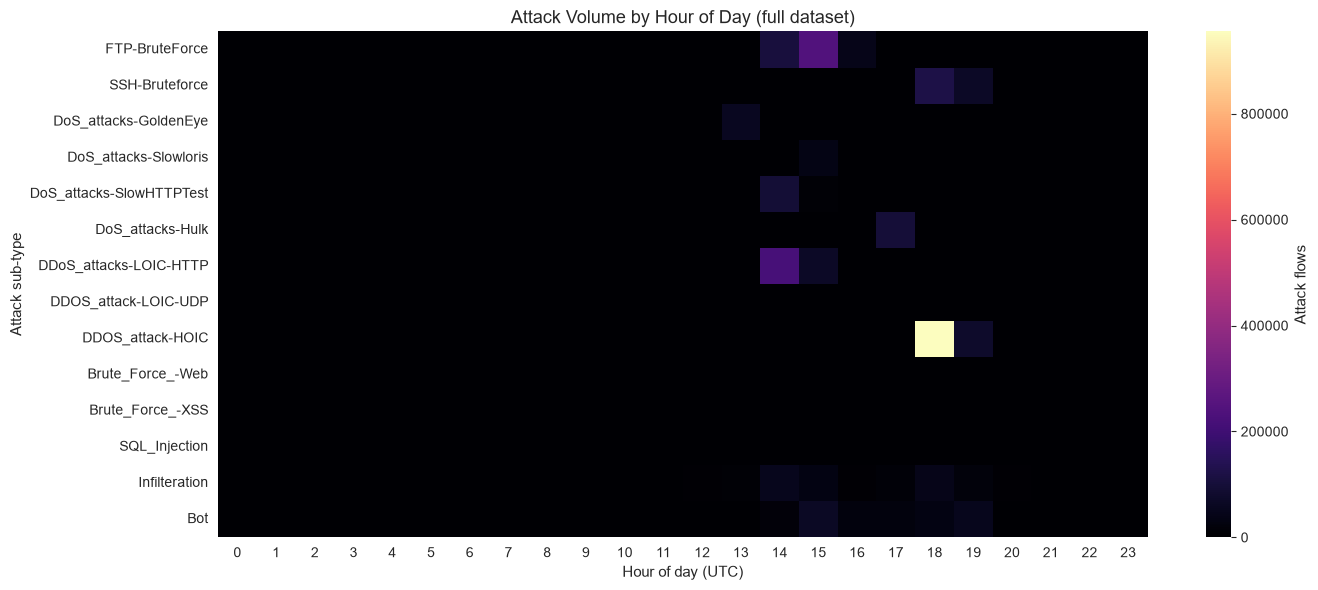

In [19]:
hour_of_day = pd.to_datetime(attack_times, unit='ms').hour
hour_table = pd.crosstab(hour_of_day, attack_codes)
hour_table.columns = [code_to_attack[c] for c in hour_table.columns]
hour_table = hour_table.reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(hour_table.T, cmap='magma', ax=ax,
            cbar_kws={'label': 'Attack flows'})
ax.set_xlabel('Hour of day (UTC)')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Volume by Hour of Day (full dataset)')
plt.tight_layout()
plt.show()


### What this means for modelling

When benign traffic is removed, the sequence is **almost entirely blocked**:

- **11 of the 14 attack types appear as exactly one block each**, covering **99.9%** of all attack flows.
- The only genuinely mixed part is the **22 Feb web-attack episode**: `Brute_Force_-Web`, `Brute_Force_-XSS` and `SQL_Injection` alternate in tiny bursts, producing 1,283 of the 1,294 blocks while making up only 0.1% of attack flows.
- The overall mixing index is ≈0.0005, which correctly says "mostly sequential" — but only the **per-attack `Runs` column** reveals the local mixing. That is why both views are included.

For modelling: a random train/test split can place parts of the same scenario block on both sides and inflate scores. Use a **time-aware split**, and report the three rare web attacks separately.


## 8. Check all attacks at once — or one at a time

The table below has **one row per attack type and a `Selected` column**. Change `SELECTION` to analyse everything together or a single attack separately.

- `'all'` → every attack type
- `'DDOS_attack-HOIC'` → one attack type
- `['DDOS_attack-HOIC', 'Bot']` → any subset


In [20]:
all_attacks = attack_df['Attack'].tolist()
SELECTION = 'all'          # 'all', 'DDOS_attack-HOIC', or ['DDOS_attack-HOIC', 'Bot']

if SELECTION == 'all':
    selected_attacks = all_attacks
elif isinstance(SELECTION, str):
    selected_attacks = [SELECTION]
else:
    selected_attacks = list(SELECTION)

unknown = [a for a in selected_attacks if a not in all_attacks]
if unknown:
    raise ValueError(f'Unknown attack(s): {unknown}. Choose from {all_attacks}')

print('All attack types :', all_attacks)
print('Selected         :', selected_attacks)


All attack types : ['DDOS_attack-HOIC', 'FTP-BruteForce', 'DDoS_attacks-LOIC-HTTP', 'Bot', 'SSH-Bruteforce', 'Infilteration', 'DoS_attacks-SlowHTTPTest', 'DoS_attacks-Hulk', 'DoS_attacks-GoldenEye', 'DoS_attacks-Slowloris', 'DDOS_attack-LOIC-UDP', 'Brute_Force_-Web', 'Brute_Force_-XSS', 'SQL_Injection']
Selected         : ['DDOS_attack-HOIC', 'FTP-BruteForce', 'DDoS_attacks-LOIC-HTTP', 'Bot', 'SSH-Bruteforce', 'Infilteration', 'DoS_attacks-SlowHTTPTest', 'DoS_attacks-Hulk', 'DoS_attacks-GoldenEye', 'DoS_attacks-Slowloris', 'DDOS_attack-LOIC-UDP', 'Brute_Force_-Web', 'Brute_Force_-XSS', 'SQL_Injection']


### Per-attack summary table

One row per attack type. **Flow counts, shares and block statistics use the full scan**; **unique IPs and mean feature values use the stratified sample** (up to 20,000 flows per attack). The `Selected` column shows which rows the next plots use.


In [21]:
summary = pd.DataFrame(index=all_attacks)
summary.index.name = 'Attack'
summary['Flows'] = [attack_counts[a] for a in all_attacks]
summary['ShareOfAttacks_%'] = (summary['Flows'] / summary['Flows'].sum() * 100).round(2)
summary['Runs'] = run_table['Runs']
summary['MeanRun'] = run_table['MeanRun']
summary['MaxRun'] = run_table['MaxRun']
summary['UniqueSrcIPs'] = df_attacks.groupby('Attack')['IPV4_SRC_ADDR'].nunique()
summary['UniqueDstIPs'] = df_attacks.groupby('Attack')['IPV4_DST_ADDR'].nunique()
summary['MeanDuration_ms'] = df_attacks.groupby('Attack')['FLOW_DURATION_MILLISECONDS'].mean().round(1)
summary['MeanIN_BYTES'] = df_attacks.groupby('Attack')['IN_BYTES'].mean().round(1)
summary['MeanOUT_BYTES'] = df_attacks.groupby('Attack')['OUT_BYTES'].mean().round(1)
summary['MeanIN_PKTS'] = df_attacks.groupby('Attack')['IN_PKTS'].mean().round(1)
summary['MeanOUT_PKTS'] = df_attacks.groupby('Attack')['OUT_PKTS'].mean().round(1)
summary['Selected'] = summary.index.isin(selected_attacks)
summary = summary.fillna(0).sort_values('Flows', ascending=False)
display(summary)


,Flows,ShareOfAttacks_%,Runs,MeanRun,MaxRun,UniqueSrcIPs,UniqueDstIPs,MeanDuration_ms,MeanIN_BYTES,MeanOUT_BYTES,MeanIN_PKTS,MeanOUT_PKTS,Selected
Attack,,,,,,,,,,,,,
DDOS_attack-HOIC,1032311,39.69,1,1032311.0,1032311,10,1,38.4,510.2,1147.0,5.0,5.0,True
FTP-BruteForce,386720,14.87,1,386720.0,386720,1,1,1.0,60.0,40.0,1.0,1.0,True
DDoS_attacks-LOIC-HTTP,288589,11.10,1,288589.0,288589,10,1,17095.1,191.3,938.2,4.1,3.3,True
Bot,207703,7.99,1,207703.0,207703,8,1,11.4,538.0,341.8,5.0,5.0,True
SSH-Bruteforce,188474,7.25,1,188474.0,188474,1,1,366.8,3171.0,3821.5,23.4,22.2,True
Infilteration,188152,7.23,1,188152.0,188152,64,285,5373.8,311.7,777.3,2.5,2.6,True
DoS_attacks-SlowHTTPTest,105550,4.06,1,105550.0,105550,1,1,1.0,60.0,40.0,1.0,1.0,True
DoS_attacks-Hulk,100076,3.85,1,100076.0,100076,1,1,80463.3,12819.0,22622.8,101.2,93.6,True
DoS_attacks-GoldenEye,61300,2.36,1,61300.0,61300,1,1,9970.9,753.7,950.1,5.2,3.2,True


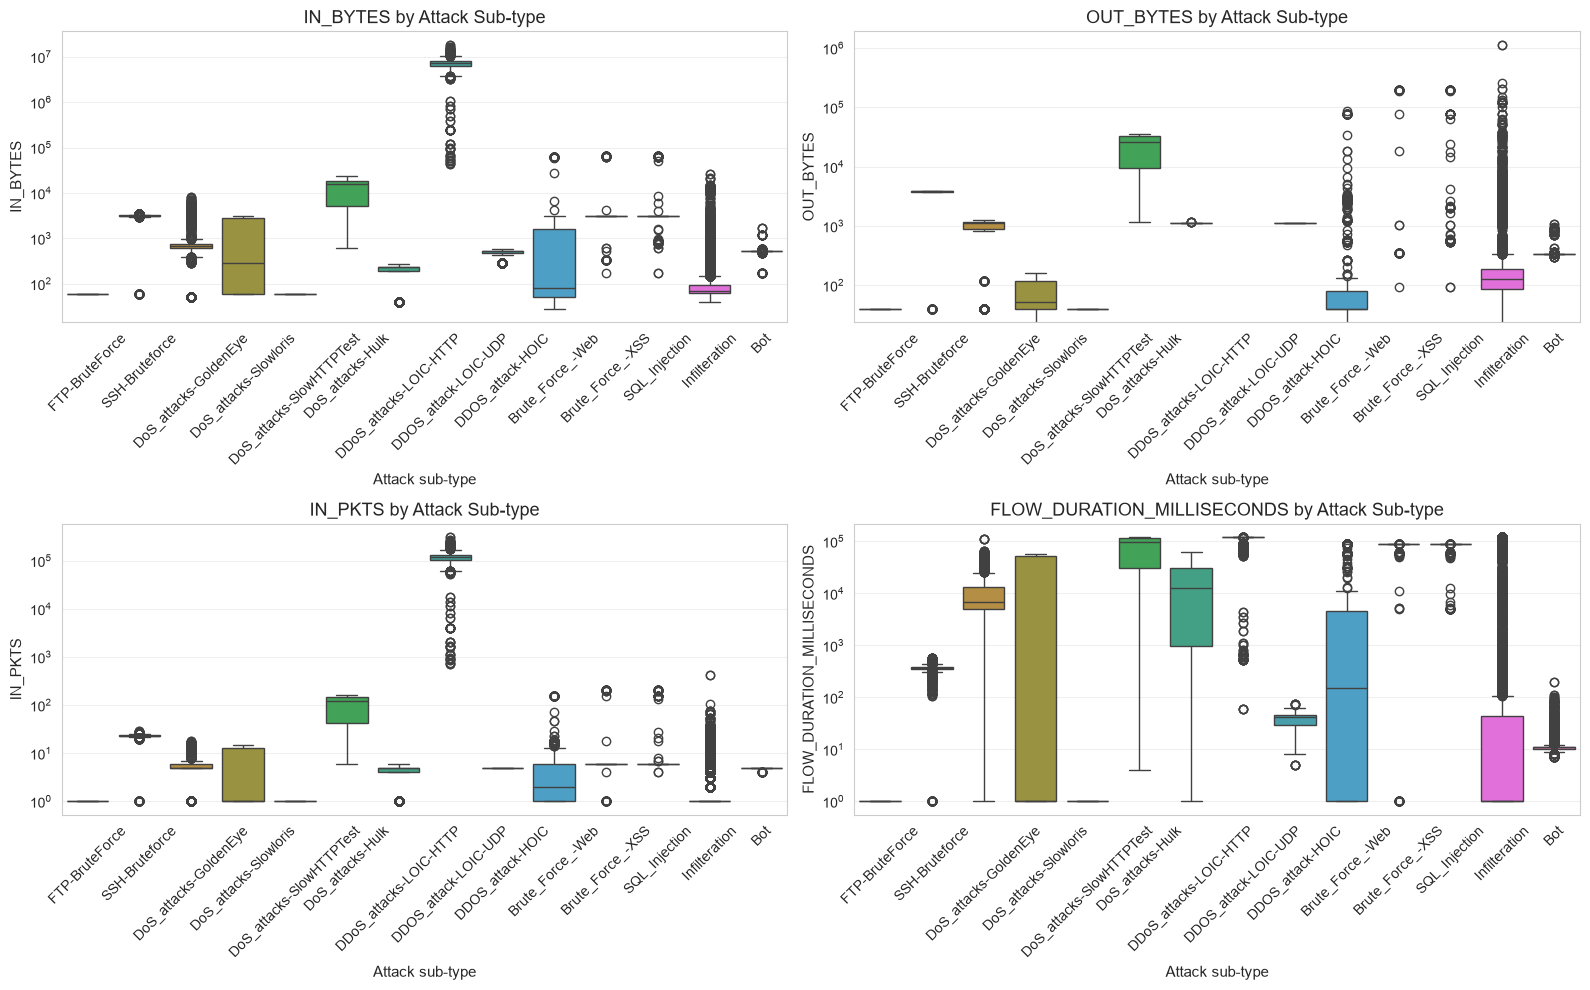

In [22]:
compare_attacks = df_attacks[df_attacks['Attack'].isin(selected_attacks)]
features = ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'FLOW_DURATION_MILLISECONDS']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=compare_attacks, x='Attack', y=feat, ax=ax, palette='husl')
    ax.set_yscale('log')
    ax.set_xlabel('Attack sub-type')
    ax.set_ylabel(feat)
    ax.set_title(f'{feat} by Attack Sub-type')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


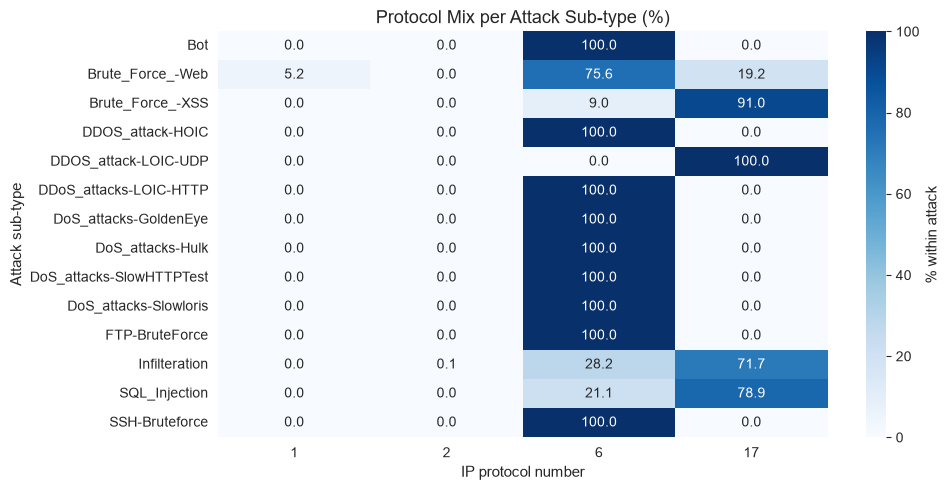

In [23]:
proto_attack = pd.crosstab(compare_attacks['Attack'], compare_attacks['PROTOCOL'],
                           normalize='index') * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(proto_attack.round(1), annot=True, fmt='.1f', cmap='Blues', ax=ax,
            cbar_kws={'label': '% within attack'})
ax.set_xlabel('IP protocol number')
ax.set_ylabel('Attack sub-type')
ax.set_title('Protocol Mix per Attack Sub-type (%)')
plt.tight_layout()
plt.show()


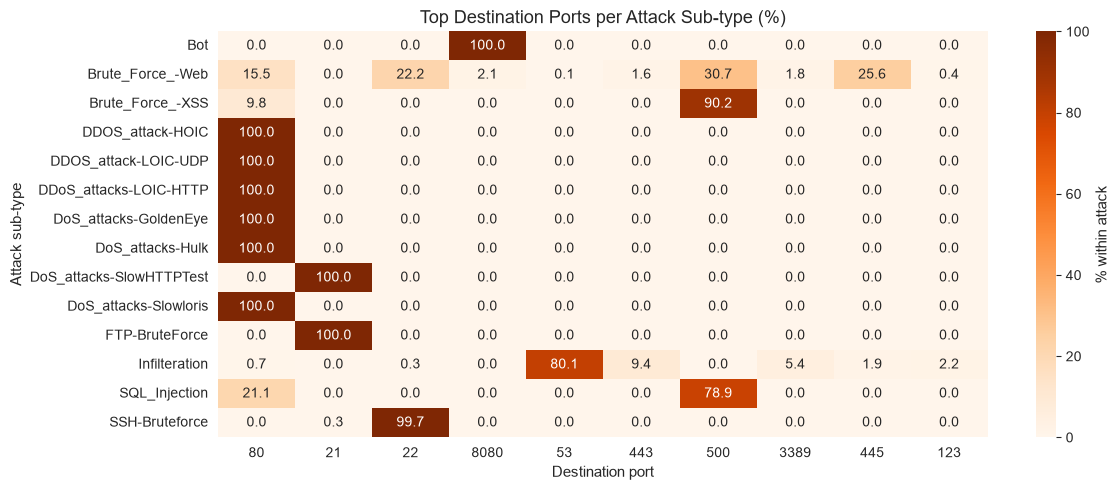

In [24]:
top_ports = compare_attacks['L4_DST_PORT'].value_counts().head(10).index
port_table = pd.crosstab(compare_attacks['Attack'], compare_attacks['L4_DST_PORT'])
port_table = port_table.reindex(columns=top_ports, fill_value=0)
port_pct = port_table.div(port_table.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(port_pct.round(1), annot=True, fmt='.1f', cmap='Oranges', ax=ax,
            cbar_kws={'label': '% within attack'})
ax.set_xlabel('Destination port')
ax.set_ylabel('Attack sub-type')
ax.set_title('Top Destination Ports per Attack Sub-type (%)')
plt.tight_layout()
plt.show()


## 9. Benign vs attack statistics

Build a comparison table from a benign sample plus the stratified attack sample, adding a `Class` column (`Benign` or the attack name) so every row is easy to filter.


In [25]:
benign_pool = df_sample[df_sample['Label'] == 0]
benign_sample = benign_pool.sample(n=min(50_000, len(benign_pool)), random_state=42)

df_compare = pd.concat([benign_sample, df_attacks], ignore_index=True)
df_compare['Class'] = df_compare['Attack']
df_compare.loc[df_compare['Label'] == 0, 'Class'] = 'Benign'

key_features = [
    'FLOW_DURATION_MILLISECONDS', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS',
    'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'MIN_TTL', 'MAX_TTL',
    'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT',
]

stats_by_label = df_compare.groupby('Label')[key_features].agg(['mean', 'median', 'std'])
stats_by_label.index = stats_by_label.index.map({0: 'Benign', 1: 'Attack'})
display(stats_by_label.round(2))


FLOW_DURATION_MILLISECONDS                    IN_BYTES         \
                             mean median       std       mean median   
Label                                                                  
Benign                   12990.37   22.0  33401.34     789.27   96.0   
Attack                   14897.73   42.0  32574.17  120209.45  501.0   

                  OUT_BYTES                    IN_PKTS  ... MIN_TTL MAX_TTL  \
              std      mean median        std     mean  ...     std    mean   
Label                                                   ...                   
Benign   29758.21   7208.18  159.0  268514.24     6.44  ...   60.17   63.87   
Attack  933700.66   3085.07  341.0    9286.49  1986.21  ...   52.46   62.10   

                     LONGEST_FLOW_PKT                SHORTEST_FLOW_PKT         \
       median    std             mean median     std              mean median   
Label                                                                           
Benign   99.0  60.24           448.65  151.0  529.31             56.12   44.0   
Attack   63.0  52.46           547.00  366.0  435.61             49.37   40.0   

               
          std  
Label          
Benign  27.75  
Attack  35.90  

[2 rows x 33 columns]

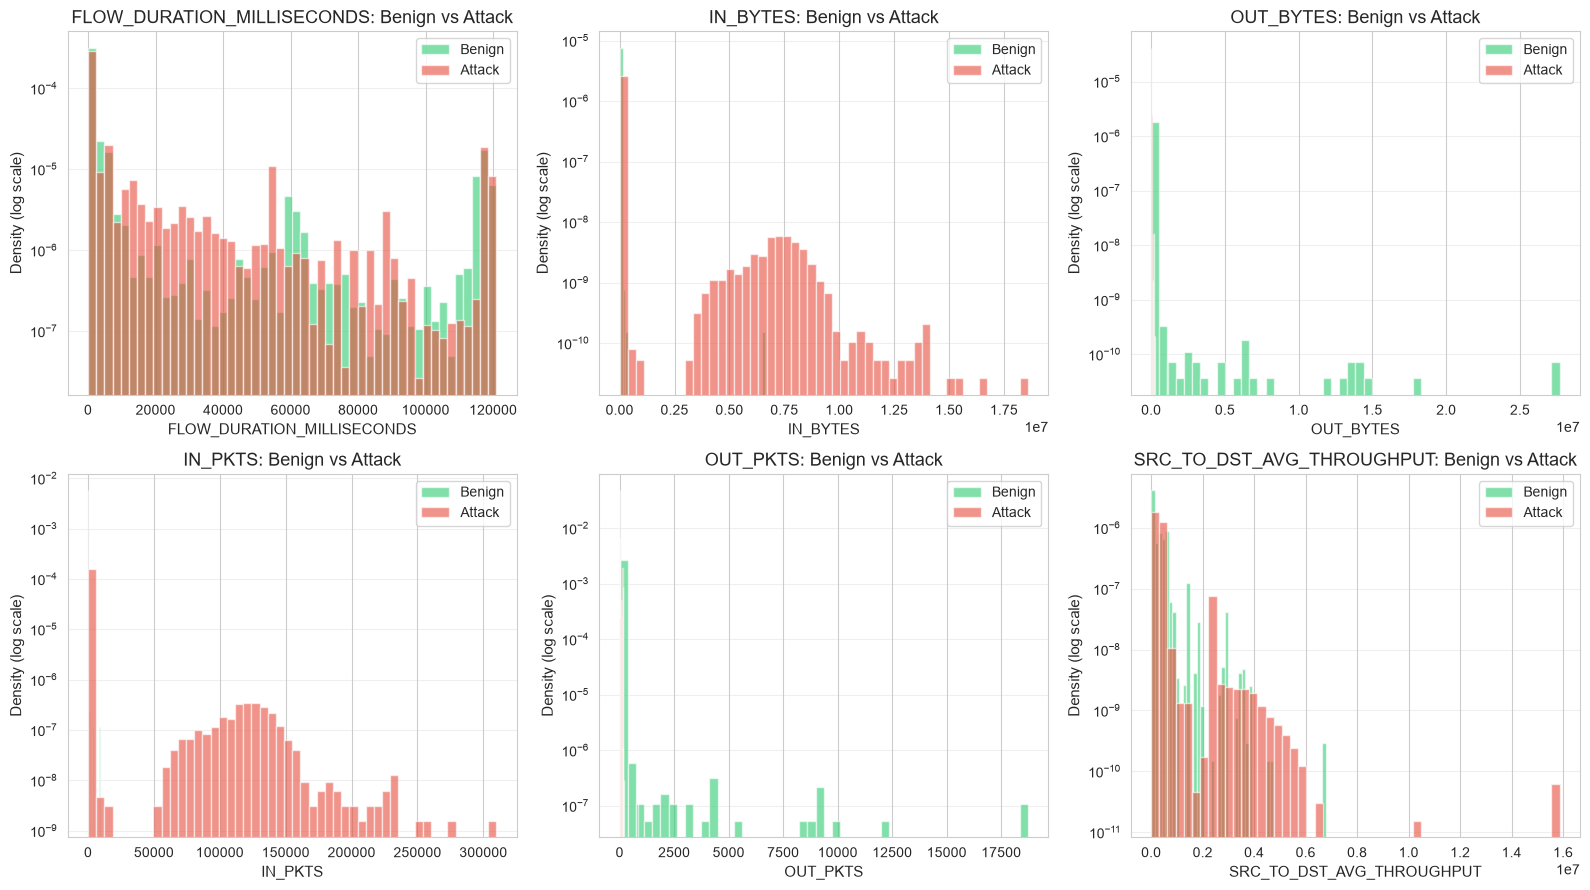

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.ravel(), key_features[:6]):
    for label, color in [(0, '#2ecc71'), (1, '#e74c3c')]:
        vals = df_compare.loc[df_compare['Label'] == label, feat]
        ax.hist(vals, bins=50, alpha=0.6, density=True, color=color,
                label='Benign' if label == 0 else 'Attack')
    ax.set_yscale('log')
    ax.set_xlabel(feat)
    ax.set_ylabel('Density (log scale)')
    ax.set_title(f'{feat}: Benign vs Attack')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


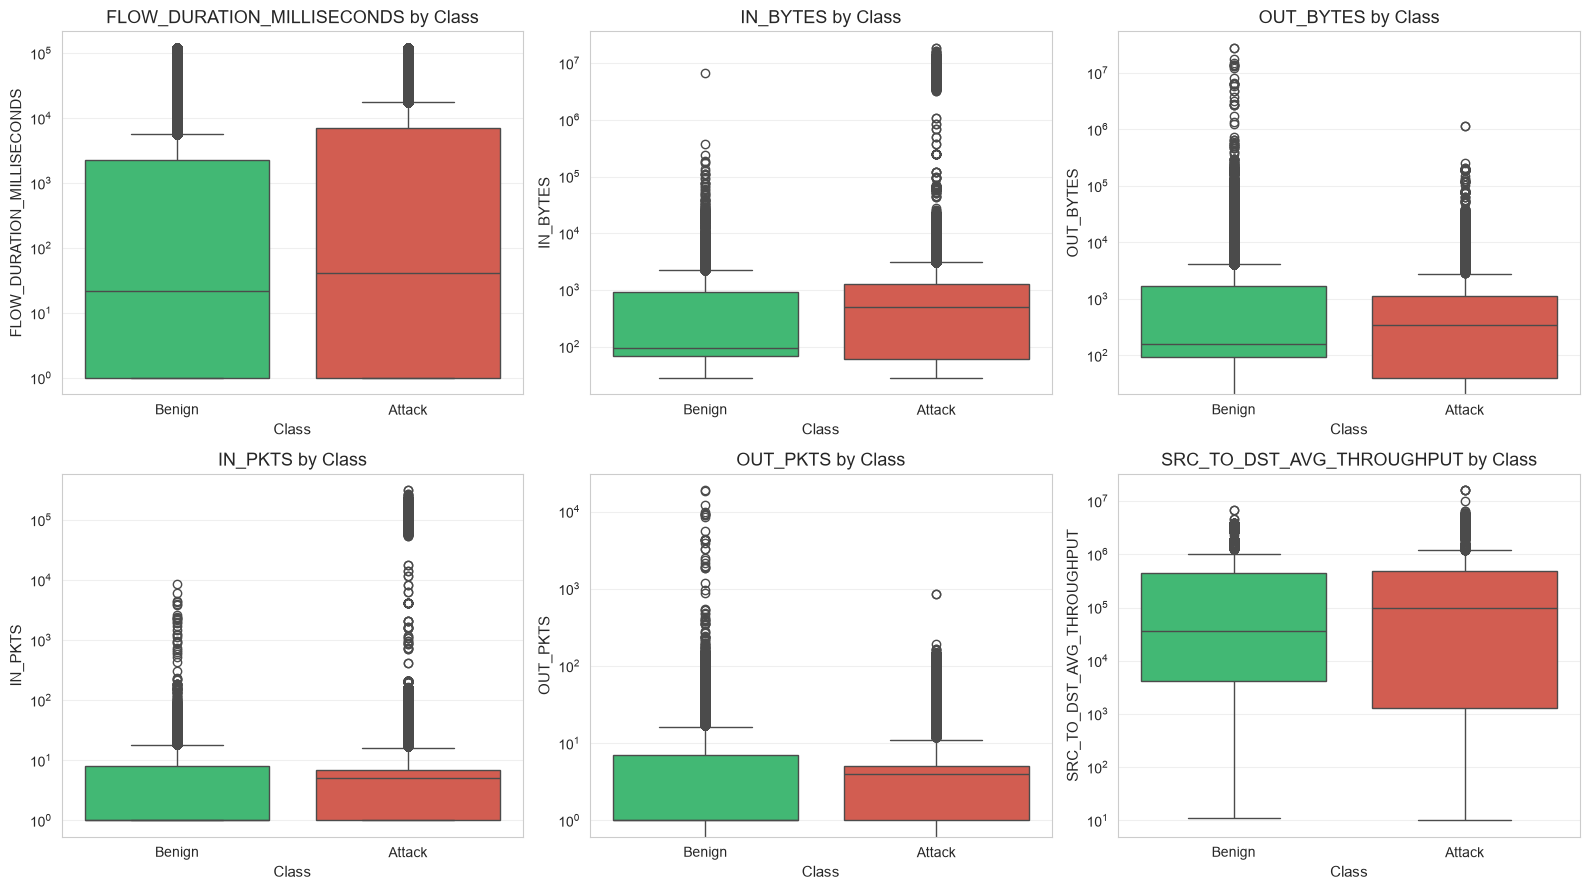

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.ravel(), key_features[:6]):
    sns.boxplot(data=df_compare, x='Label', y=feat, ax=ax,
                palette=['#2ecc71', '#e74c3c'])
    ax.set_yscale('log')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Benign', 'Attack'])
    ax.set_xlabel('Class')
    ax.set_ylabel(feat)
    ax.set_title(f'{feat} by Class')
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Protocol analysis

Full-file IP protocol counts, plus the protocol mix inside each attack type.


,Protocol,Flows,Name,Percent
0,6,12345696,TCP,61.37
1,17,7702479,UDP,38.29
2,1,30084,ICMP,0.15
3,58,18745,ICMPv6,0.09
4,2,18512,IGMP,0.09
5,47,13,GRE,0.00


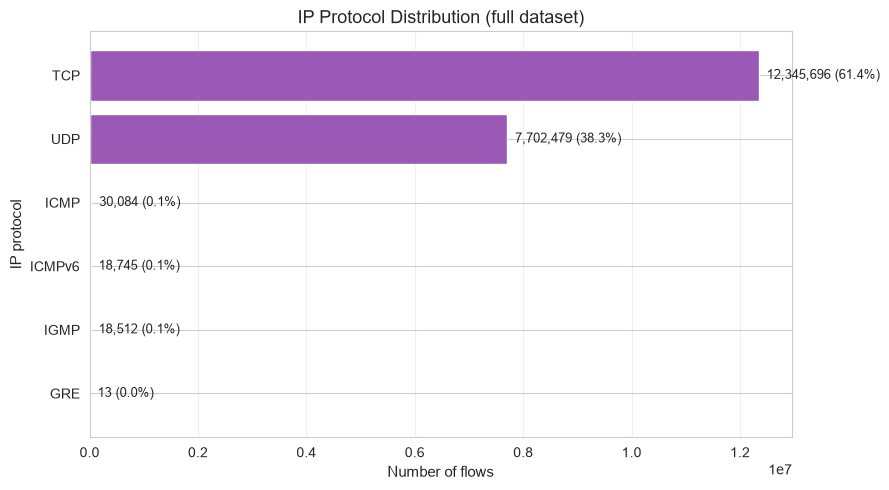

In [28]:
PROTOCOL_MAP = {1: 'ICMP', 2: 'IGMP', 6: 'TCP', 17: 'UDP', 47: 'GRE',
                50: 'ESP', 51: 'AH', 58: 'ICMPv6', 89: 'OSPF', 132: 'SCTP'}

proto_df = pd.DataFrame(proto_counts.items(), columns=['Protocol', 'Flows'])
proto_df['Protocol'] = pd.to_numeric(proto_df['Protocol'], errors='coerce').fillna(-1).astype(int)
proto_df['Name'] = proto_df['Protocol'].map(PROTOCOL_MAP).fillna('Other')
proto_df['Percent'] = (proto_df['Flows'] / total_rows * 100).round(2)
proto_df = proto_df.sort_values('Flows', ascending=False)
display(proto_df)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(proto_df['Name'][::-1], proto_df['Flows'][::-1], color='#9b59b6')
ax.set_xlabel('Number of flows')
ax.set_ylabel('IP protocol')
ax.set_title('IP Protocol Distribution (full dataset)')
for i, (v, p) in enumerate(zip(proto_df['Flows'][::-1], proto_df['Percent'][::-1])):
    ax.text(v, i, f'  {v:,} ({p:.1f}%)', va='center', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Port analysis

Top source and destination ports over the full file, using well-known service names where possible.


,Port,Flows,Service
0,53,7323736,DNS
1,3389,3037595,RDP
2,443,2865361,HTTPS
3,80,2839365,HTTP
4,445,1016905,SMB
5,21,495156,FTP
6,22,226587,SSH
7,8080,218674,HTTP-Alt
8,23,130334,TELNET
9,5355,102580,Other


,Port,Flows,Service
0,3389,706869,RDP
1,443,98922,HTTPS
2,0,67358,Ephemeral/Other
3,138,60764,Ephemeral/Other
4,546,38125,Ephemeral/Other
5,123,32825,NTP
6,445,26831,SMB
7,49672,26041,Ephemeral/Other
8,80,23577,HTTP
9,54193,23271,Ephemeral/Other


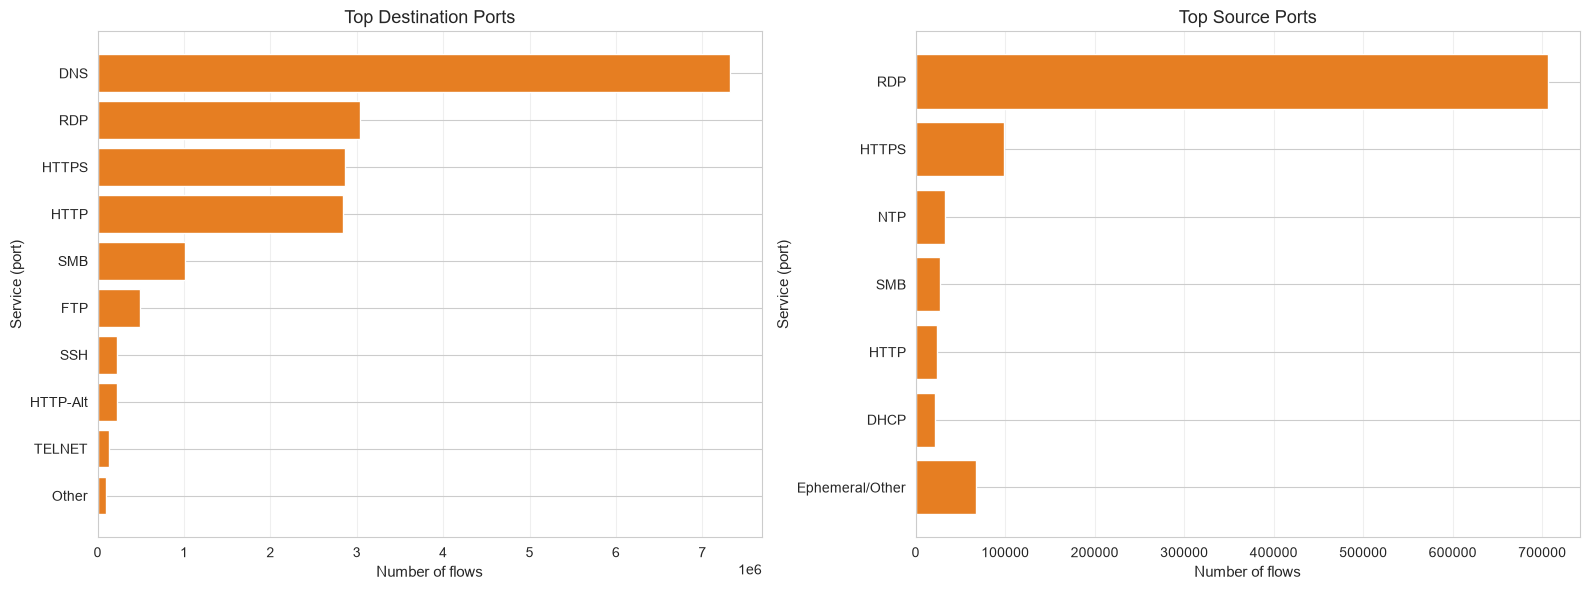

In [29]:
WELL_KNOWN_PORTS = {
    20: 'FTP-DATA', 21: 'FTP', 22: 'SSH', 23: 'TELNET', 25: 'SMTP',
    53: 'DNS', 67: 'DHCP', 68: 'DHCP', 69: 'TFTP', 80: 'HTTP',
    110: 'POP3', 123: 'NTP', 139: 'NetBIOS', 143: 'IMAP', 161: 'SNMP',
    443: 'HTTPS', 445: 'SMB', 993: 'IMAPS', 995: 'POP3S', 1433: 'MSSQL',
    3306: 'MySQL', 3389: 'RDP', 5432: 'PostgreSQL', 5900: 'VNC',
    8080: 'HTTP-Alt', 27017: 'MongoDB',
}

dst_df = pd.DataFrame(dst_port_counts.items(), columns=['Port', 'Flows'])
dst_df['Service'] = dst_df['Port'].map(WELL_KNOWN_PORTS).fillna('Other')
dst_df = dst_df.sort_values('Flows', ascending=False).head(15)

src_df = pd.DataFrame(src_port_counts.items(), columns=['Port', 'Flows'])
src_df['Service'] = src_df['Port'].map(WELL_KNOWN_PORTS).fillna('Ephemeral/Other')
src_df = src_df.sort_values('Flows', ascending=False).head(15)

display(dst_df.reset_index(drop=True))
display(src_df.reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, frame, title in [(axes[0], dst_df, 'Top Destination Ports'),
                         (axes[1], src_df, 'Top Source Ports')]:
    ax.barh(frame['Service'][::-1], frame['Flows'][::-1], color='#e67e22')
    ax.set_xlabel('Number of flows')
    ax.set_ylabel('Service (port)')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 12. IP address analysis

How many endpoints are there, which IPs dominate, and how many unique IPs each attack type touches.


Unique source IPs      : 13,646
Unique destination IPs : 5,320


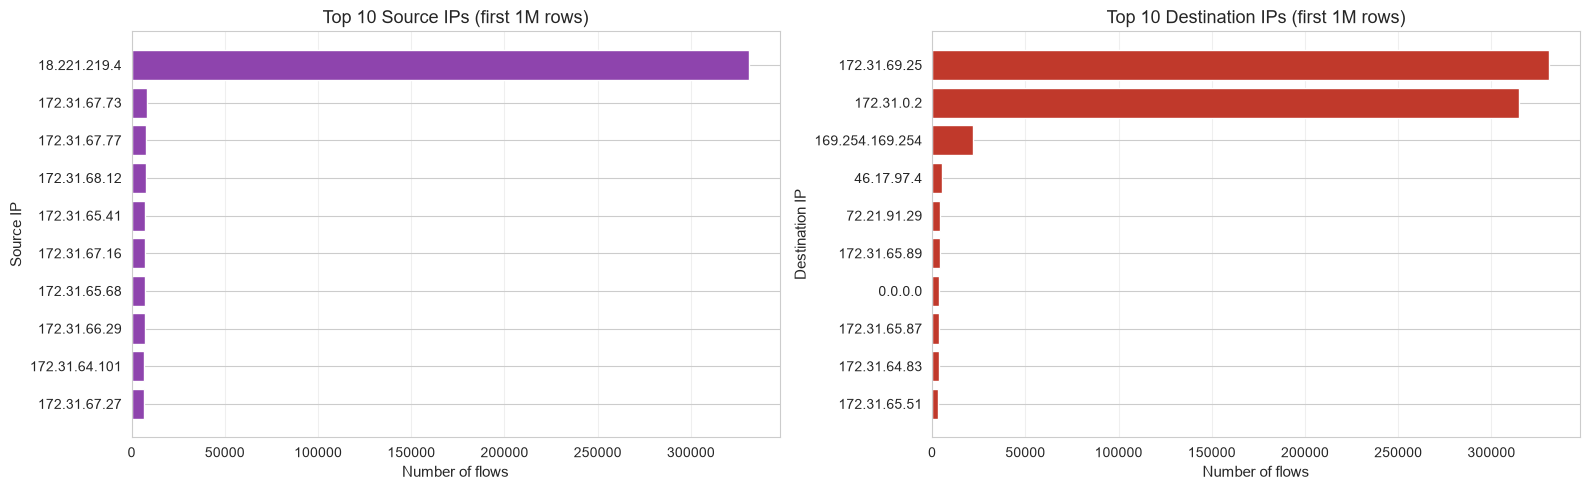

,UniqueSrcIPs,UniqueDstIPs
Attack,,
Brute_Force_-Web,561,1
Infilteration,64,285
DDoS_attacks-LOIC-HTTP,10,1
DDOS_attack-LOIC-UDP,10,1
DDOS_attack-HOIC,10,1
Bot,8,1
Brute_Force_-XSS,4,2
SQL_Injection,4,1
DoS_attacks-GoldenEye,1,1


In [30]:
print(f'Unique source IPs      : {df_sample["IPV4_SRC_ADDR"].nunique():,}')
print(f'Unique destination IPs : {df_sample["IPV4_DST_ADDR"].nunique():,}')

top_src = df_sample['IPV4_SRC_ADDR'].value_counts().head(10)
top_dst = df_sample['IPV4_DST_ADDR'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(top_src.index[::-1], top_src.values[::-1], color='#8e44ad')
axes[0].set_xlabel('Number of flows')
axes[0].set_ylabel('Source IP')
axes[0].set_title('Top 10 Source IPs (first 1M rows)')
axes[0].grid(axis='x', alpha=0.3)

axes[1].barh(top_dst.index[::-1], top_dst.values[::-1], color='#c0392b')
axes[1].set_xlabel('Number of flows')
axes[1].set_ylabel('Destination IP')
axes[1].set_title('Top 10 Destination IPs (first 1M rows)')
axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

attack_ips = df_attacks.groupby('Attack')[['IPV4_SRC_ADDR', 'IPV4_DST_ADDR']].nunique()
attack_ips.columns = ['UniqueSrcIPs', 'UniqueDstIPs']
display(attack_ips.sort_values('UniqueSrcIPs', ascending=False))


## 13. Temporal analysis

Flow volume by hour of day and over the capture timeline.


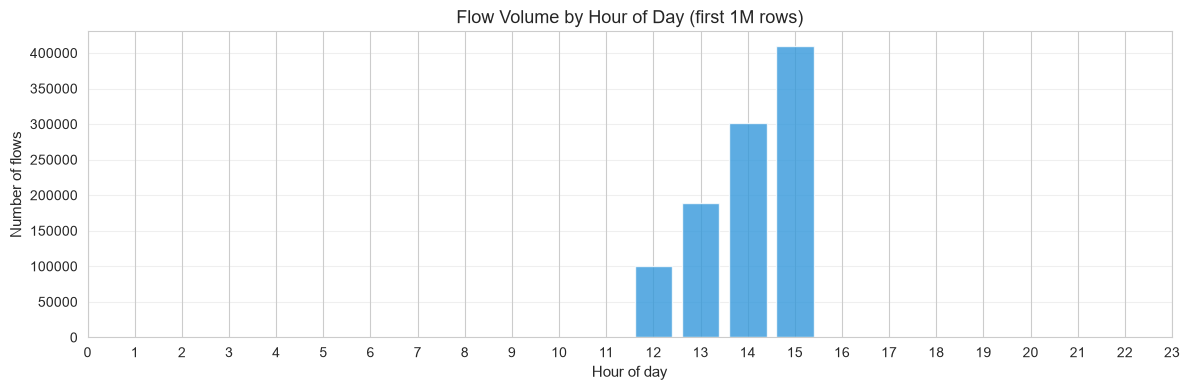

In [31]:
df_sample['flow_start_dt'] = pd.to_datetime(df_sample['FLOW_START_MILLISECONDS'], unit='ms')
hourly = df_sample['flow_start_dt'].dt.hour.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(hourly.index, hourly.values, color='#3498db', alpha=0.8)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Number of flows')
ax.set_title('Flow Volume by Hour of Day (first 1M rows)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


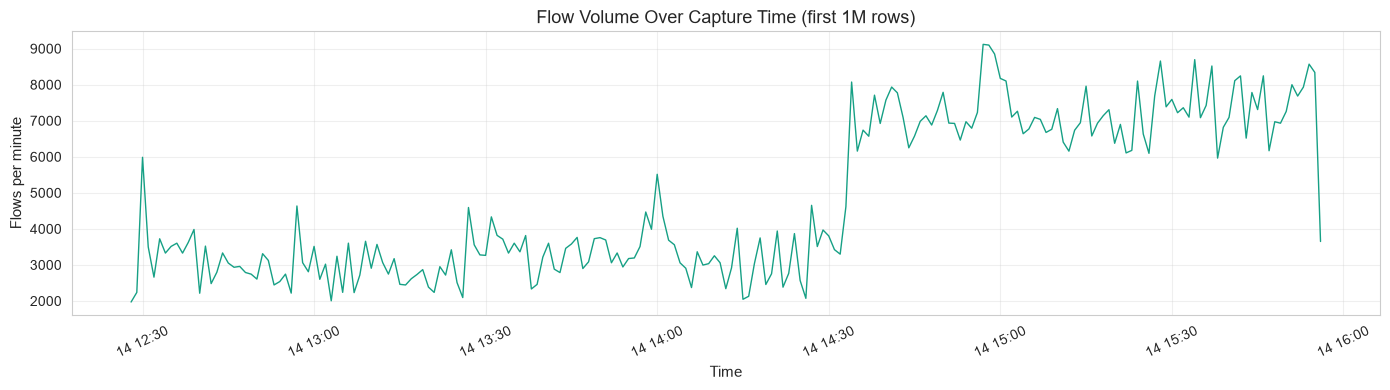

In [32]:
per_minute = df_sample.set_index('flow_start_dt').resample('1min').size()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(per_minute.index, per_minute.values, color='#16a085', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('Flows per minute')
ax.set_title('Flow Volume Over Capture Time (first 1M rows)')
ax.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


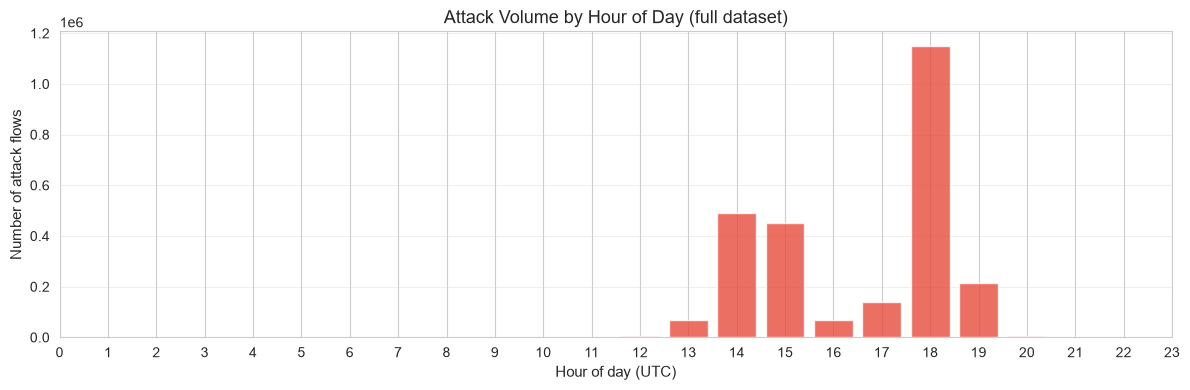

In [33]:
attack_hour = pd.Series(pd.to_datetime(attack_times, unit='ms').hour).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(attack_hour.index, attack_hour.values, color='#e74c3c', alpha=0.8)
ax.set_xlabel('Hour of day (UTC)')
ax.set_ylabel('Number of attack flows')
ax.set_title('Attack Volume by Hour of Day (full dataset)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 14. Feature correlation

Correlation among key numeric features. Strongly correlated pairs are redundant for modelling.


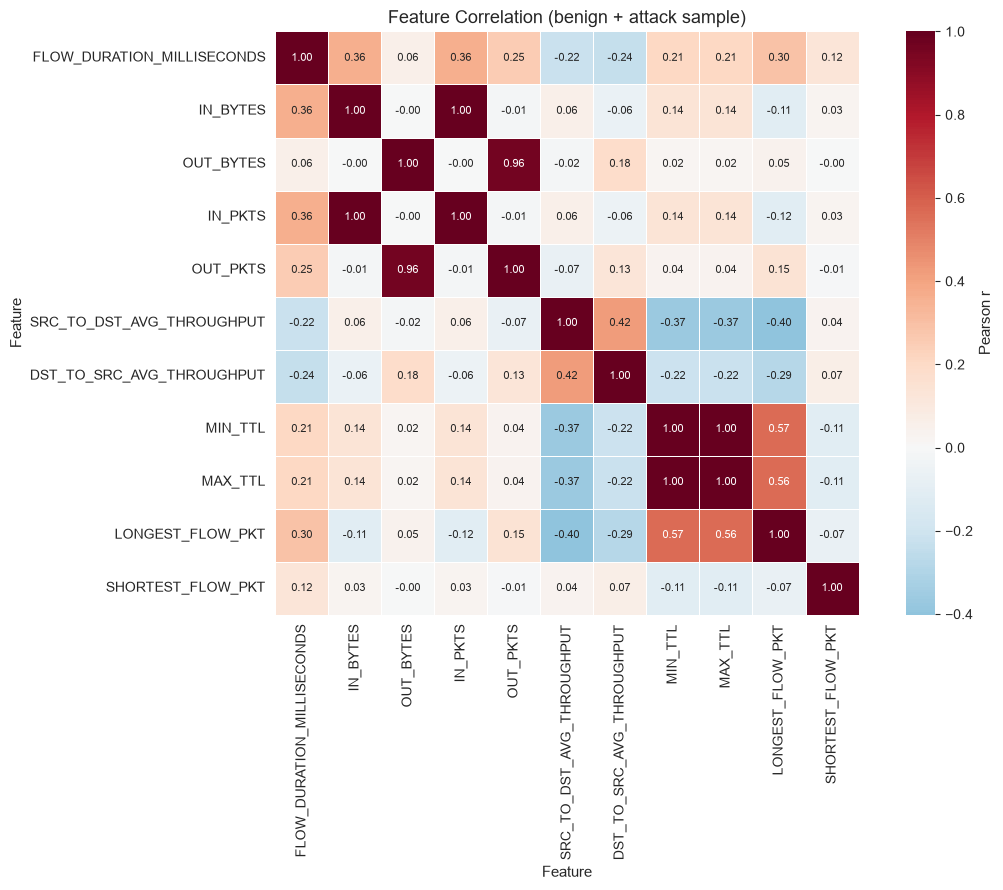

Pairs with |r| > 0.8:


,Feature 1,Feature 2,r
0,IN_BYTES,IN_PKTS,1.000
1,OUT_BYTES,OUT_PKTS,0.959
2,MIN_TTL,MAX_TTL,1.000


In [34]:
corr = df_compare[key_features].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True,
            linewidths=0.5, ax=ax, annot_kws={'size': 8},
            cbar_kws={'label': 'Pearson r'})
ax.set_xlabel('Feature')
ax.set_ylabel('Feature')
ax.set_title('Feature Correlation (benign + attack sample)')
plt.tight_layout()
plt.show()

high = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]
        if abs(value) > 0.8:
            high.append({'Feature 1': corr.columns[i],
                         'Feature 2': corr.columns[j],
                         'r': round(value, 3)})
print('Pairs with |r| > 0.8:')
display(pd.DataFrame(high) if high else pd.DataFrame({'Note': ['None found']}))


## 15. Missing and infinite values

Check the sample for missing (`NaN`) and infinite (`inf`) values.


In [35]:
missing = df_sample.isnull().sum()
missing_df = (missing[missing > 0]
              .rename('MissingCount')
              .to_frame())
missing_df['MissingPercent'] = (missing_df['MissingCount'] / len(df_sample) * 100).round(4)
print(f'Columns with missing values: {len(missing_df)}')
display(missing_df.sort_values('MissingCount', ascending=False) if len(missing_df) else pd.DataFrame({'Note': ['No missing values']}))

numeric = df_sample.select_dtypes(include=[np.number])
inf_counts = np.isinf(numeric).sum()
inf_df = inf_counts[inf_counts > 0].rename('InfiniteCount').to_frame()
print(f'Columns with infinite values: {len(inf_df)}')
display(inf_df.sort_values('InfiniteCount', ascending=False) if len(inf_df) else pd.DataFrame({'Note': ['No infinite values']}))


Columns with missing values: 0


,Note
0,No missing values


Columns with infinite values: 0


,Note
0,No infinite values


## 16. Summary & key insights

The next cell prints the headline numbers directly from the full-dataset scan.


In [36]:
print('=' * 60)
print('NF-CICIDS2018 v3 - DATASET SUMMARY')
print('=' * 60)
print(f'Total flows          : {total_rows:,}')
print(f'Benign               : {label_counts[0]:,} ({label_counts[0] / total_rows * 100:.1f}%)')
print(f'Attack               : {label_counts[1]:,} ({label_counts[1] / total_rows * 100:.1f}%)')
print(f'Attack types         : {len(attack_counts)}')
print(f'Attack blocks (runs) : {n_runs:,}')
print(f'Mixing index         : {mixing_index:.4f} -> {verdict}')
print()
print('Per-attack flow counts:')
for name in attack_df['Attack']:
    row = attack_df.set_index('Attack').loc[name]
    print(f'  {name:26s} {int(row["Flows"]):>12,}  ({row["PercentOfAttacks"]:.2f}% of attacks)')
print()
print('Most common attack   :', attack_df.iloc[0]['Attack'])
print('Rarest attack        :', attack_df.iloc[-1]['Attack'])


NF-CICIDS2018 v3 - DATASET SUMMARY
Total flows          : 20,115,529
Benign               : 17,514,626 (87.1%)
Attack               : 2,600,903 (12.9%)
Attack types         : 14
Attack blocks (runs) : 1,294
Mixing index         : 0.0005 -> mostly BLOCKED / sequential

Per-attack flow counts:
  DDOS_attack-HOIC              1,032,311  (39.69% of attacks)
  FTP-BruteForce                  386,720  (14.87% of attacks)
  DDoS_attacks-LOIC-HTTP          288,589  (11.10% of attacks)
  Bot                             207,703  (7.99% of attacks)
  SSH-Bruteforce                  188,474  (7.25% of attacks)
  Infilteration                   188,152  (7.23% of attacks)
  DoS_attacks-SlowHTTPTest        105,550  (4.06% of attacks)
  DoS_attacks-Hulk                100,076  (3.85% of attacks)
  DoS_attacks-GoldenEye            61,300  (2.36% of attacks)
  DoS_attacks-Slowloris            36,040  (1.39% of attacks)
  DDOS_attack-LOIC-UDP              3,450  (0.13% of attacks)
  Brute_Force_-Web    

### Key takeaways

1. **14 attack types, very uneven support.** `DDOS_attack-HOIC` alone is ~40% of attack flows; `SQL_Injection` (440 flows), `Brute_Force_-XSS` (480) and `Brute_Force_-Web` (1,618) are extremely rare.
2. **The first 1M rows are not representative.** They contain benign traffic plus only `FTP-BruteForce`, and attacks are 33% of that slice vs 13% of the full file. Always scan the full file for attack-level conclusions.
3. **The sequence is mostly blocked, with one mixed episode.** 11 of 14 attacks form exactly one block each (99.9% of attack flows). Only the 22 Feb web attacks interleave, producing 1,283 tiny blocks. Overall mixing index ≈ 0.0005.
4. **Per-attack behaviour differs.** Duration, bytes, ports and protocols vary strongly by attack type, which is why multiclass models can outperform a single binary detector.
5. **The capture is scenario-per-day.** Blocks line up with dates, so random splits can leak the same scenario into training and testing.

### Recommendations

- Use time-aware train/validation/test splits (split by capture date).
- Handle class imbalance with stratified sampling, class weights, or focal loss.
- Evaluate with macro-F1 and per-class recall, not accuracy alone.
- Drop one of each highly correlated feature pair.
- Report per-class metrics for the three rare web attacks; consider grouping them if support is too low.

---

*End of notebook*
